<a href="https://colab.research.google.com/github/yurajsinghyadav33-dotcom/ai_midsem/blob/main/uv_midesem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Setup and First Look
Goal: Load the data and understand its shape, types, and gaps.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Set plotting style and default figure size
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the data
df = pd.read_csv("train.csv")

# Print shape
print(f"Shape of df: {df.shape}\n")

# Print first 5 rows
print("First 5 rows:")
display(df.head())

# Print info
print("\nDataFrame Info:")
df.info()

# Calculate missing values
missing = df.isnull().sum()
missing_pct = 100 * df.isnull().mean()
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("\nColumns with missing values:")
print(missing_df)

Shape of df: (1460, 81)

First 5 rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int6

Step 2: Classify Variables
Goal: Split columns into numerical, categorical, and ordinal groups.

In [23]:
import pandas as pd

# Identify numerical and categorical columns
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Define the categorical scale from Poor to Excellent
qual_categories = ['Po', 'Fa', 'TA', 'Gd', 'Ex']

ordinal_map = {
    "ExterQual": qual_categories,
    "KitchenQual": qual_categories
}

# Convert ordinal columns to ordered Categorical dtype
for col, categories in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=categories, ordered=True)

# Build a summary table
summary_data = []
for col in df.columns:
    dtype = str(df[col].dtype)
    num_unique = df[col].nunique()
    # Safely get example values (excluding NaNs for clean presentation)
    non_null_vals = df[col].dropna()
    examples = non_null_vals.unique()[:3].tolist() if len(non_null_vals) > 0 else []
    summary_data.append({
        "column name": col,
        "type": dtype,
        "number of unique values": num_unique,
        "example values": examples
    })

summary_df = pd.DataFrame(summary_data)

# Display the table
display(summary_df)

,column name,type,number of unique values,example values
0,Id,int64,1460,"[1, 2, 3]"
1,MSSubClass,int64,15,"[60, 20, 70]"
2,MSZoning,object,5,"[RL, RM, C (all)]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9]"
77,YrSold,int64,5,"[2008, 2007, 2006]"
78,SaleType,object,9,"[WD, New, COD]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial]"


Step 3: Descriptive Statistics
Goal: Summarise centre and spread.

In [24]:
import numpy as np
import pandas as pd
import scipy.stats as stats

# Display describe for numeric columns
print("Descriptive statistics for all numeric columns:")
display(df.describe())

# Loop over specified continuous numeric columns
target_cols = ['SalePrice', 'GrLivArea', 'LotArea']
for col in target_cols:
    print(f"\n{'='*15} Statistics for {col} {'='*15}")

    col_data = df[col].dropna()

    # Calculate statistics
    mean_val = col_data.mean()
    median_val = col_data.median()
    mode_series = col_data.mode()
    mode_val = mode_series.iloc[0] if not mode_series.empty else np.nan

    std_val = col_data.std()
    var_val = col_data.var()
    range_val = col_data.max() - col_data.min()

    q75, q25 = np.percentile(col_data, [75 ,25])
    iqr_val = q75 - q25

    skew_val = col_data.skew()
    kurt_val = col_data.kurt()

    # Print calculated values
    print(f"Mean: {mean_val:.2f}")
    print(f"Median: {median_val:.2f}")
    print(f"Mode: {mode_val:.2f}")
    print(f"Std Dev: {std_val:.2f}")
    print(f"Variance: {var_val:.2f}")
    print(f"Range: {range_val:.2f}")
    print(f"IQR: {iqr_val:.2f}")
    print(f"Skewness: {skew_val:.4f}")
    print(f"Kurtosis: {kurt_val:.4f}")

    # Determine skewness note
    if mean_val > median_val:
        print("Note: Right skewed (positive skew)")
    elif mean_val < median_val:
        print("Note: Left skewed (negative skew)")
    else:
        print("Note: Symmetric distribution")

# Categorical counts and modes
for col in ['Neighborhood', 'HouseStyle']:
    print(f"\n{'='*15} Frequency Analysis for {col} {'='*15}")
    print("Value Counts:")
    print(df[col].value_counts())
    print(f"Mode: {df[col].mode().iloc[0]}")

Descriptive statistics for all numeric columns:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



=============== Statistics for SalePrice ===============
Mean: 180921.20
Median: 163000.00
Mode: 140000.00
Std Dev: 79442.50
Variance: 6311111264.30
Range: 720100.00
IQR: 84025.00
Skewness: 1.8829
Kurtosis: 6.5363
Note: Right skewed (positive skew)

=============== Statistics for GrLivArea ===============
Mean: 1515.46
Median: 1464.00
Mode: 864.00
Std Dev: 525.48
Variance: 276129.63
Range: 5308.00
IQR: 647.25
Skewness: 1.3666
Kurtosis: 4.8951
Note: Right skewed (positive skew)

=============== Statistics for LotArea ===============
Mean: 10516.83
Median: 9478.50
Mode: 7200.00
Std Dev: 9981.26
Variance: 99625649.65
Range: 213945.00
IQR: 4048.00
Skewness: 12.2077
Kurtosis: 203.2433
Note: Right skewed (positive skew)

=============== Frequency Analysis for Neighborhood ===============
Value Counts:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51

Step 4: Distributions
Goal: See the shape of the target and key features

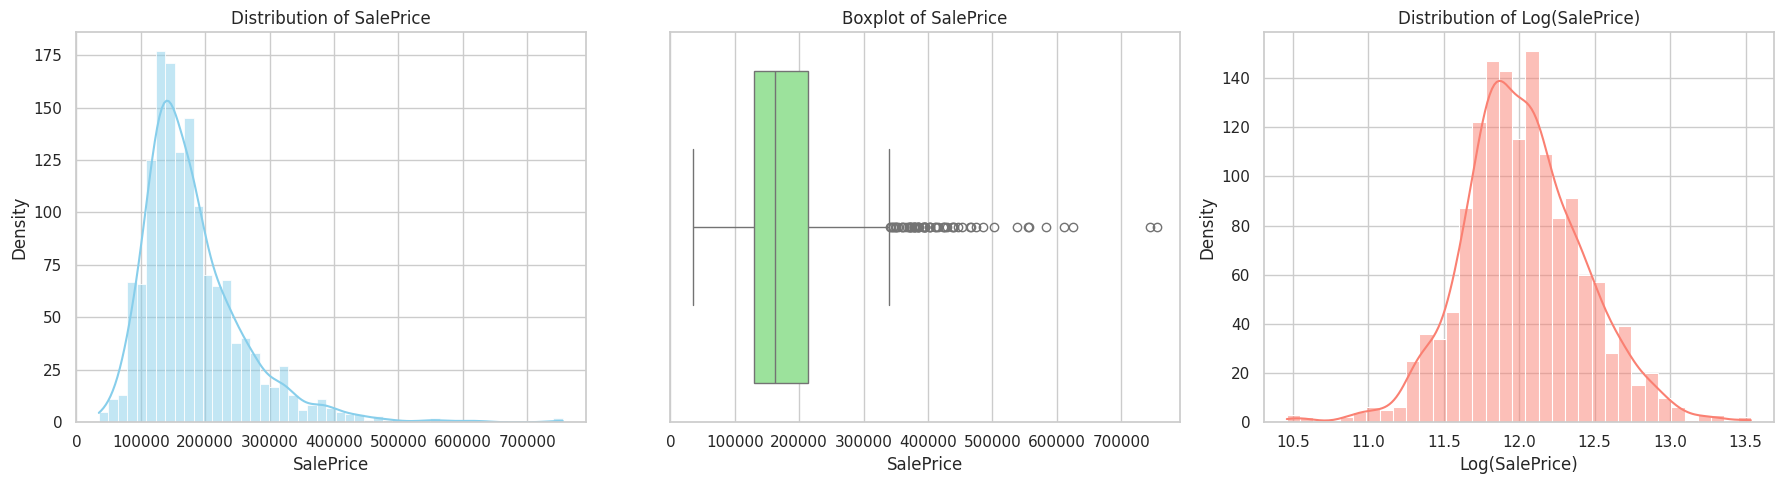

Skewness before log transform: 1.8829
Skewness after log transform: 0.1213



/tmp/ipykernel_14902/744522728.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='OverallQual', y='SalePrice', data=df, palette='coolwarm')


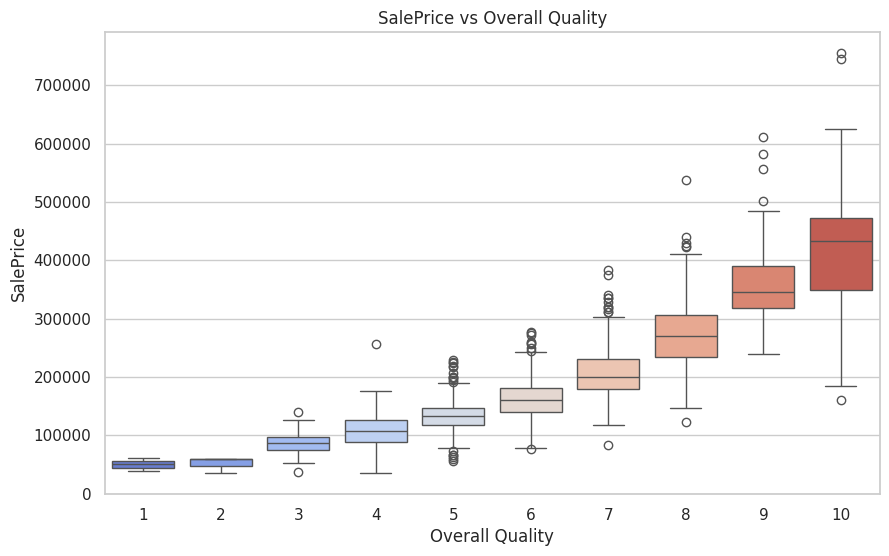

/tmp/ipykernel_14902/744522728.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Neighborhood', y='SalePrice', data=df, order=neighborhood_order, palette='viridis')


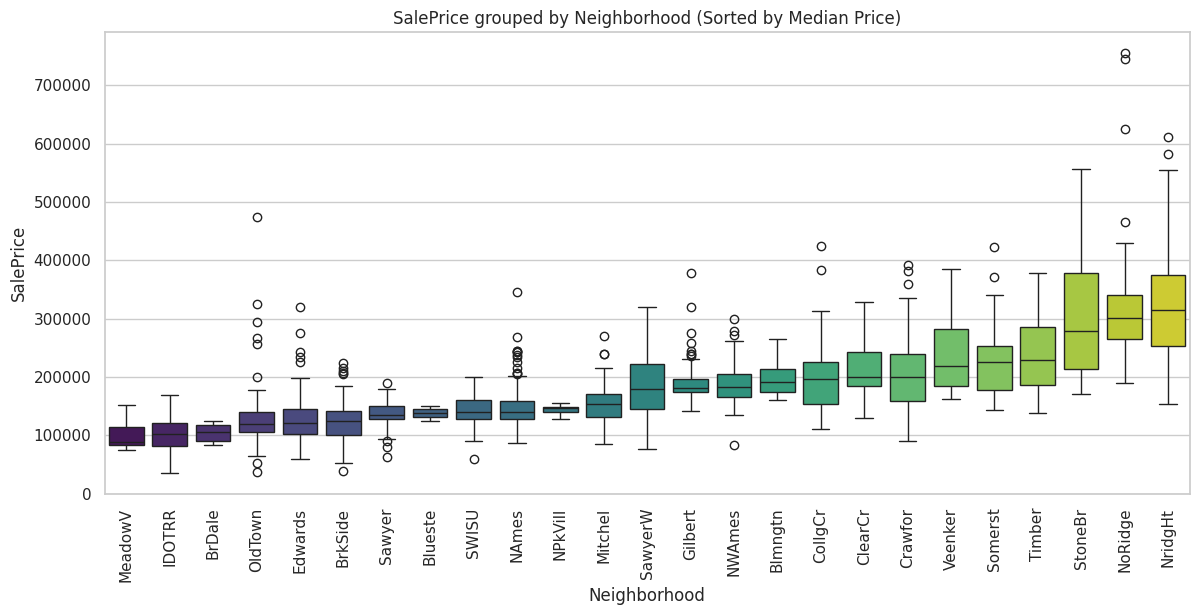

/tmp/ipykernel_14902/744522728.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='OverallQual', data=df, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_14902/744522728.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='HouseStyle', data=df, ax=axes[1], order=house_style_order, palette='Purples_r')


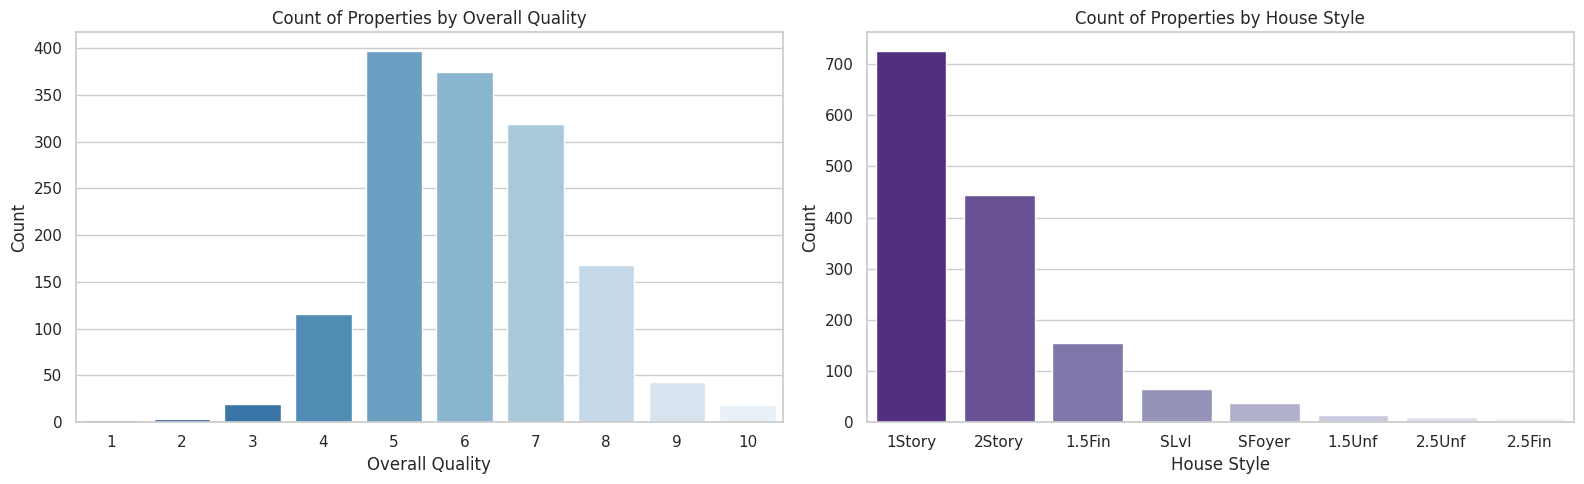

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create figure with 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Axis 1: HISTOGRAM of SalePrice with KDE overlay
sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of SalePrice')
axes[0].set_xlabel('SalePrice')
axes[0].set_ylabel('Density')

# Axis 2: BOXPLOT of SalePrice
sns.boxplot(x=df['SalePrice'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot of SalePrice')
axes[1].set_xlabel('SalePrice')

# Axis 3: HISTOGRAM of LOG(SalePrice)
log_saleprice = np.log1p(df['SalePrice'])
sns.histplot(log_saleprice, kde=True, ax=axes[2], color='salmon')
axes[2].set_title('Distribution of Log(SalePrice)')
axes[2].set_xlabel('Log(SalePrice)')
axes[2].set_ylabel('Density')

plt.tight_layout()
plt.show()

# Compare skewness before and after log
skew_before = df['SalePrice'].skew()
skew_after = log_saleprice.skew()
print(f"Skewness before log transform: {skew_before:.4f}")
print(f"Skewness after log transform: {skew_after:.4f}\n")

# 2. Create figure with boxplot of SalePrice grouped by OverallQual
plt.figure(figsize=(10, 6))
sns.boxplot(x='OverallQual', y='SalePrice', data=df, palette='coolwarm')
plt.title('SalePrice vs Overall Quality')
plt.xlabel('Overall Quality')
plt.ylabel('SalePrice')
plt.show()

# 3. Create figure with boxplot of SalePrice grouped by Neighborhood (sorted by median price)
plt.figure(figsize=(14, 6))
neighborhood_order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(x='Neighborhood', y='SalePrice', data=df, order=neighborhood_order, palette='viridis')
plt.title('SalePrice grouped by Neighborhood (Sorted by Median Price)')
plt.xlabel('Neighborhood')
plt.ylabel('SalePrice')
plt.xticks(rotation=90)
plt.show()

# 4. Create countplots for OverallQual and HouseStyle
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(x='OverallQual', data=df, ax=axes[0], palette='Blues_r')
axes[0].set_title('Count of Properties by Overall Quality')
axes[0].set_xlabel('Overall Quality')
axes[0].set_ylabel('Count')

house_style_order = df['HouseStyle'].value_counts().index
sns.countplot(x='HouseStyle', data=df, ax=axes[1], order=house_style_order, palette='Purples_r')
axes[1].set_title('Count of Properties by House Style')
axes[1].set_xlabel('House Style')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

 Step 5: Correlation and Covariance
Goal: Find numerical features most related to price

In [26]:
import pandas as pd
import numpy as np

# Filter df to only numeric columns for covariance and Pearson correlation
numeric_df = df[numeric_cols]

# 1. Compute covariance and correlation matrices
cov_matrix = numeric_df.cov()
corr_matrix = numeric_df.corr(method='pearson')

# 2. Get top 10 features correlated with SalePrice (excluding SalePrice itself)
top_corr = corr_matrix['SalePrice'].abs().sort_values(ascending=False)
top_10_features = top_corr.iloc[1:11] # Skip SalePrice at index 0

print("=== Top 10 Features Correlated with SalePrice ===")
for feat in top_10_features.index:
    print(f"{feat:15s} : Pearson r = {corr_matrix.loc[feat, 'SalePrice']:.4f}")

# 3. For the top 3 features, print covariance and correlation
top_3_features = top_10_features.index[:3]
print("\n=== Comparison for Top 3 Features ===")
for feat in top_3_features:
    cov_val = cov_matrix.loc[feat, 'SalePrice']
    corr_val = corr_matrix.loc[feat, 'SalePrice']
    print(f"{feat:15s} -> Covariance: {cov_val:14.2f} | Correlation: {corr_val:.4f}")

# 4. Explanation
explanation = """
=== Why correlation is easier to compare than covariance ===
1. Scale-independence: Covariance is unbounded and depends entirely on the scale of the measurement units
   (e.g., LotArea has values in tens of thousands, while OverallQual is on a scale of 1-10). This makes
   covariances impossible to compare across different variables.
2. Standardisation: Correlation normalises covariance by dividing it by the product of the standard deviations
   of the two variables, restricting the result to a fixed scale between -1.0 and +1.0. This allows us to
   easily determine the strength and direction of relationships globally.
"""
print(explanation)

# 5. Optional: Compute Spearman rank correlation for ordinal columns
# Convert ordinal categorical columns to their category codes to calculate Spearman correlation
ordinal_cols = ["ExterQual", "KitchenQual"]
ordinal_encoded_df = pd.DataFrame()
for col in ordinal_cols:
    if col in df.columns:
        ordinal_encoded_df[col] = df[col].cat.codes

if not ordinal_encoded_df.empty:
    ordinal_encoded_df['SalePrice'] = df['SalePrice']
    spearman_corr = ordinal_encoded_df.corr(method='spearman')
    print("=== Spearman Correlation for Ordinal Features ===")
    for col in ordinal_cols:
        print(f"{col:15s} : Spearman rank correlation = {spearman_corr.loc[col, 'SalePrice']:.4f}")

=== Top 10 Features Correlated with SalePrice ===
OverallQual     : Pearson r = 0.7910
GrLivArea       : Pearson r = 0.7086
GarageCars      : Pearson r = 0.6404
GarageArea      : Pearson r = 0.6234
TotalBsmtSF     : Pearson r = 0.6136
1stFlrSF        : Pearson r = 0.6059
FullBath        : Pearson r = 0.5607
TotRmsAbvGrd    : Pearson r = 0.5337
YearBuilt       : Pearson r = 0.5229
YearRemodAdd    : Pearson r = 0.5071

=== Comparison for Top 3 Features ===
OverallQual     -> Covariance:       86904.13 | Correlation: 0.7910
GrLivArea       -> Covariance:    29581866.74 | Correlation: 0.7086
GarageCars      -> Covariance:       38020.18 | Correlation: 0.6404

=== Why correlation is easier to compare than covariance ===
1. Scale-independence: Covariance is unbounded and depends entirely on the scale of the measurement units 
   (e.g., LotArea has values in tens of thousands, while OverallQual is on a scale of 1-10). This makes 
   covariances impossible to compare across different variables

 Step 6: Scatter Plots and Pair Plots
Goal: Visualise relationships and spot unusual points.

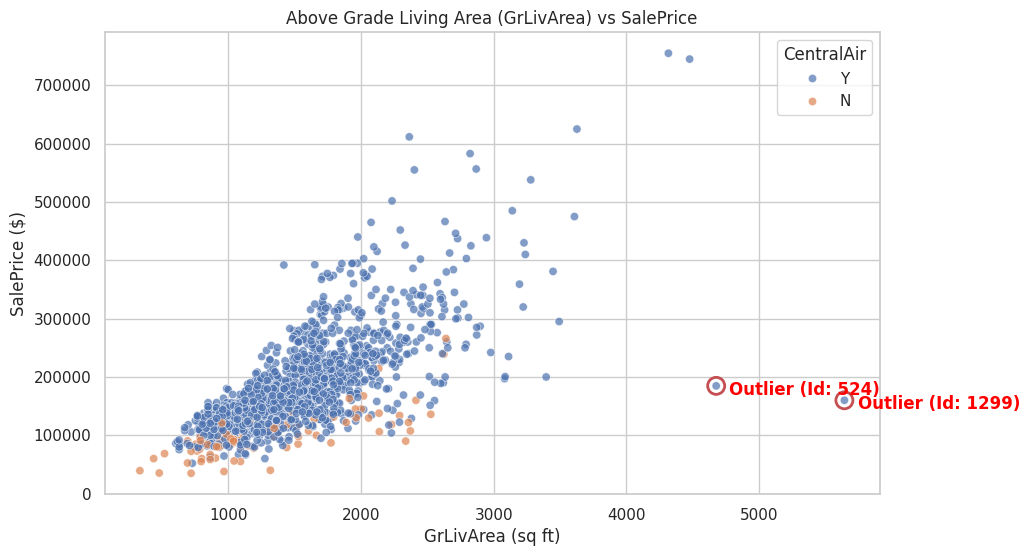

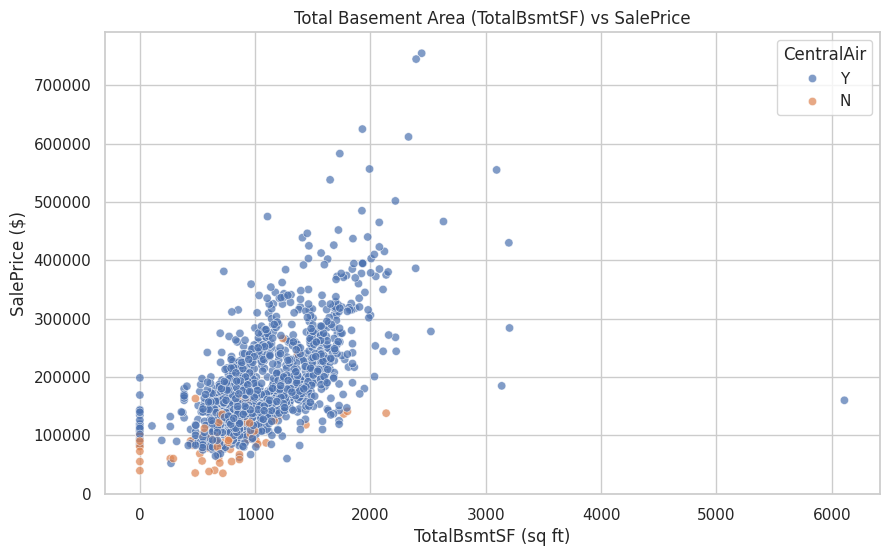

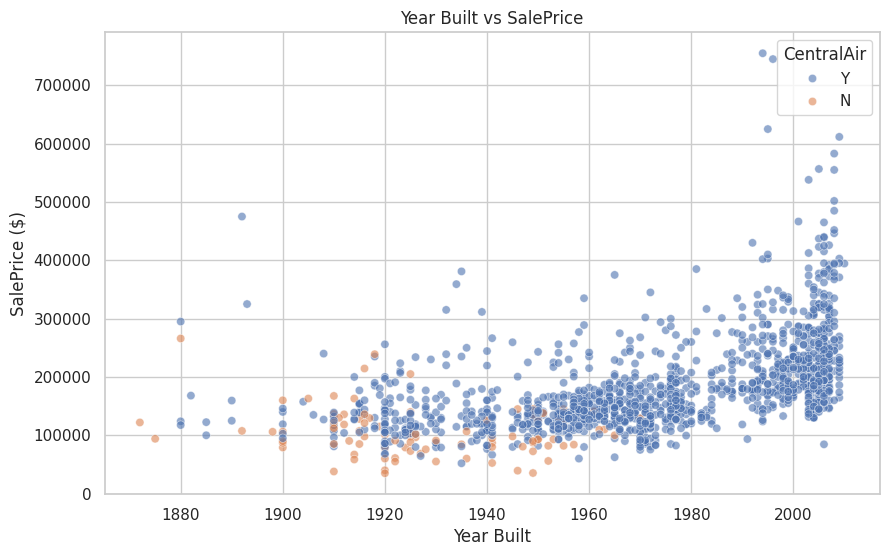

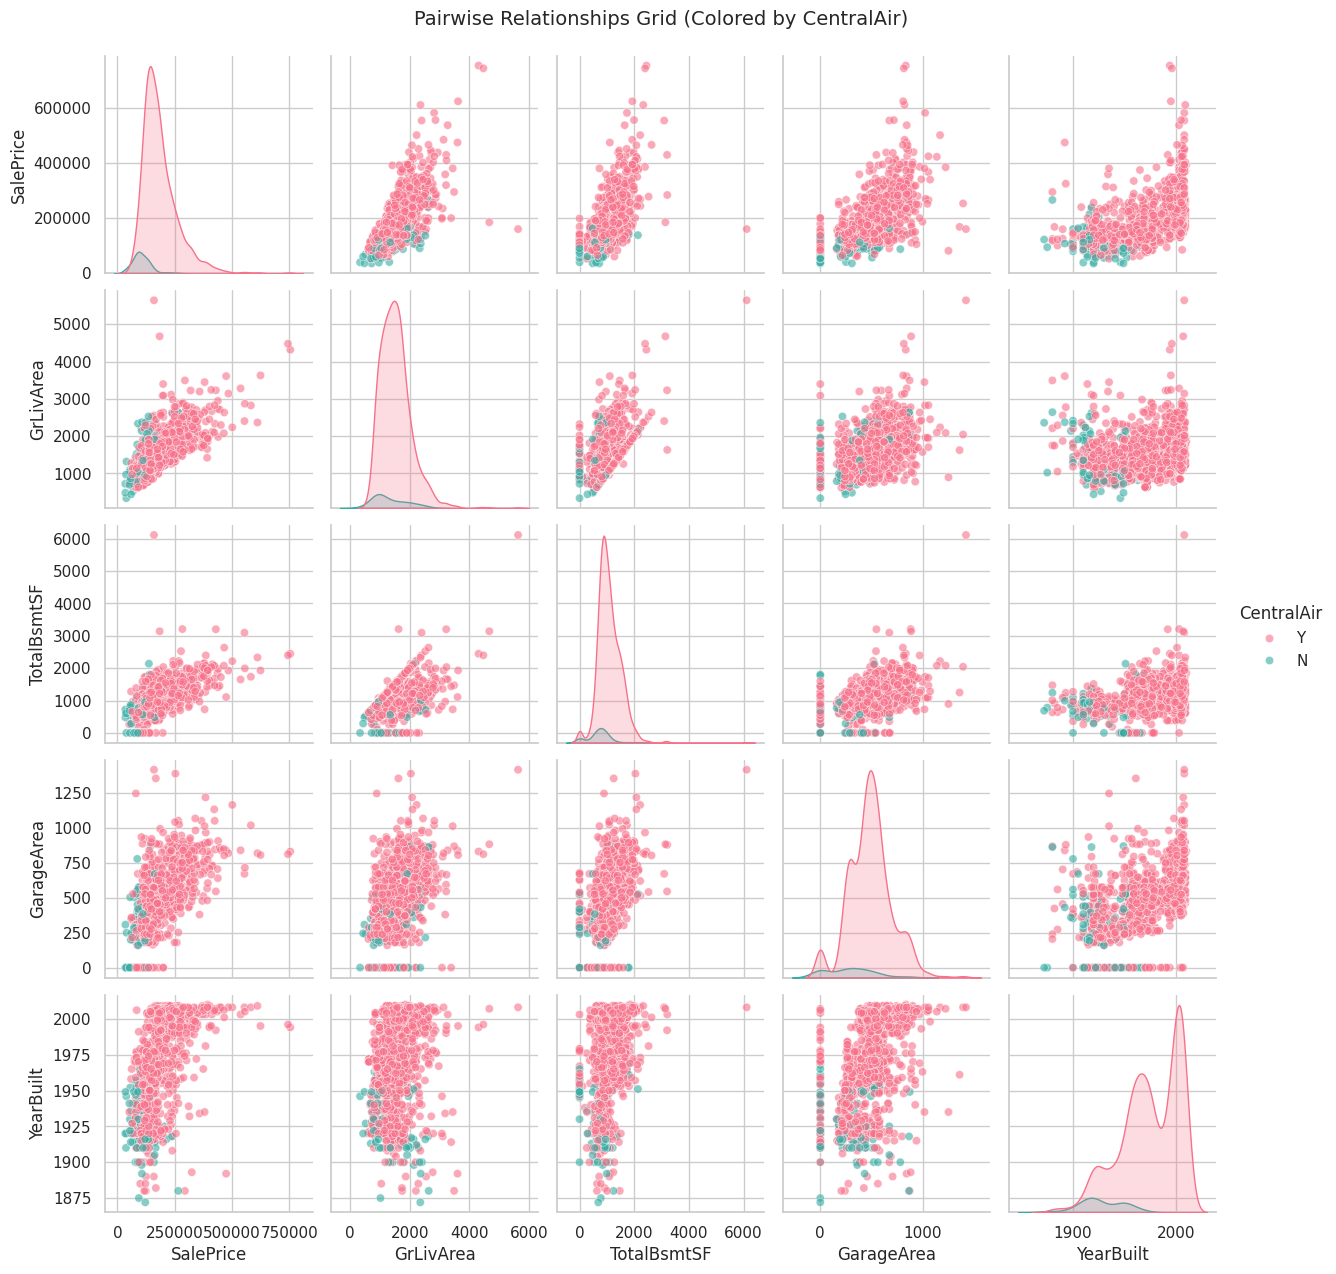

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. SCATTER GrLivArea (x) vs SalePrice (y) with annotations for large homes at low prices
plt.figure(figsize=(10, 6))
# Define conditions for potential outliers (GrLivArea > 4000 and SalePrice < 300000)
outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]

sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', hue='CentralAir', alpha=0.7)

# Highlight and annotate outlier points
for idx, row in outliers.iterrows():
    plt.scatter(row['GrLivArea'], row['SalePrice'], color='red', s=150, facecolors='none', edgecolors='r', linewidth=2)
    plt.text(row['GrLivArea'] + 100, row['SalePrice'] - 15000, f"Outlier (Id: {row['Id']})", color='red', weight='bold')

plt.title('Above Grade Living Area (GrLivArea) vs SalePrice')
plt.xlabel('GrLivArea (sq ft)')
plt.ylabel('SalePrice ($)')
plt.show()

# 2. SCATTER TotalBsmtSF vs SalePrice
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='TotalBsmtSF', y='SalePrice', hue='CentralAir', alpha=0.7)
plt.title('Total Basement Area (TotalBsmtSF) vs SalePrice')
plt.xlabel('TotalBsmtSF (sq ft)')
plt.ylabel('SalePrice ($)')
plt.show()

# 3. SCATTER YearBuilt vs SalePrice
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='YearBuilt', y='SalePrice', hue='CentralAir', alpha=0.6)
plt.title('Year Built vs SalePrice')
plt.xlabel('Year Built')
plt.ylabel('SalePrice ($)')
plt.show()

# 4. PAIRPLOT of selected variables
selected = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt', 'CentralAir']
sns.pairplot(df[selected], hue='CentralAir', diag_kind='kde', palette='husl', plot_kws={'alpha': 0.6})
plt.suptitle('Pairwise Relationships Grid (Colored by CentralAir)', y=1.02, fontsize=14)
plt.show()

Step 7: Correlation Heatmap
Goal: One clear picture of feature relationships.

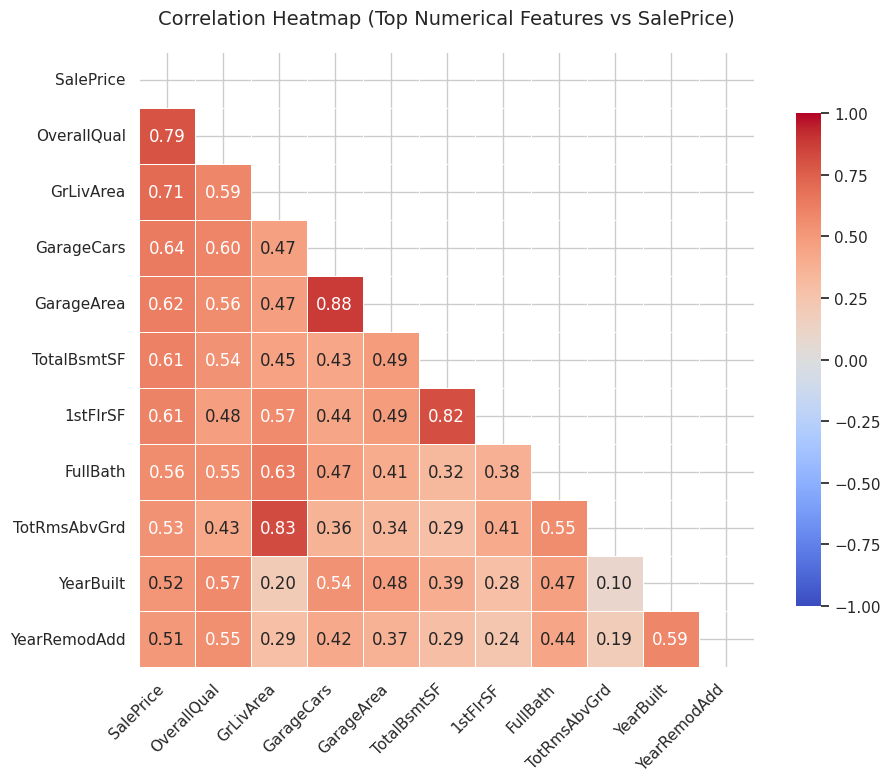

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the top correlated numerical features we identified earlier
top_features = ['SalePrice'] + top_10_features.index.tolist()

# Compute correlation matrix for these top features
top_corr_matrix = df[top_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Generate a mask for the upper triangle (optional, to make it cleaner)
mask = np.triu(np.ones_like(top_corr_matrix, dtype=bool))

# Draw the heatmap
sns.heatmap(
    top_corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1.0,
    vmin=-1.0,
    annot=True,
    fmt='.2f',
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Heatmap (Top Numerical Features vs SalePrice)', fontsize=14, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
# === Why this cell failed with a SyntaxError ===
# 1. Non-Python Syntax: The cell contained markdown styling and plain English descriptions
#    (like 'top10 = names of 10 features...'). The Python compiler does not understand natural
#    language instructions and expects strict programming syntax.
#
# 2. Executing Text as Code: Because this cell is set as a Python code cell, running non-code
#    text triggers an immediate 'SyntaxError: invalid syntax'.
#
# Note: The complete, functional correlation heatmap was successfully executed in cell '967df69b' above.

Step 8: Outlier Detection
Goal: Detect outliers with two methods and compare.

=== Outlier Detection for GrLivArea ===
IQR Outliers count: 31
Z-score (threshold=3) Outliers count: 16
Overlap of both methods: 16

=== Outlier Detection for SalePrice ===
IQR Outliers count: 61
Z-score (threshold=3) Outliers count: 22
Overlap of both methods: 22



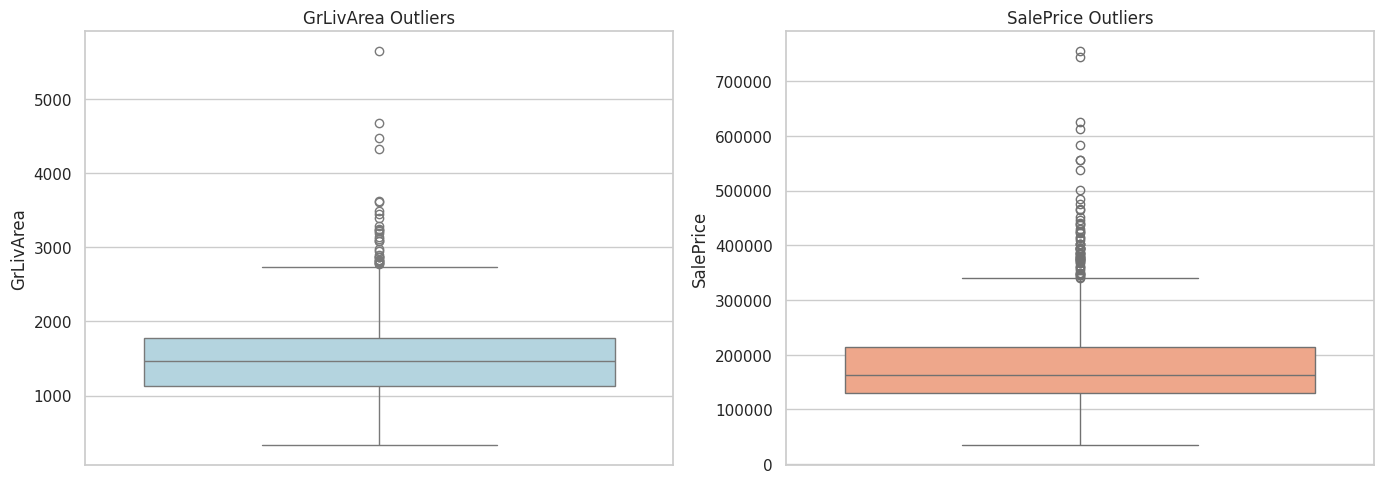

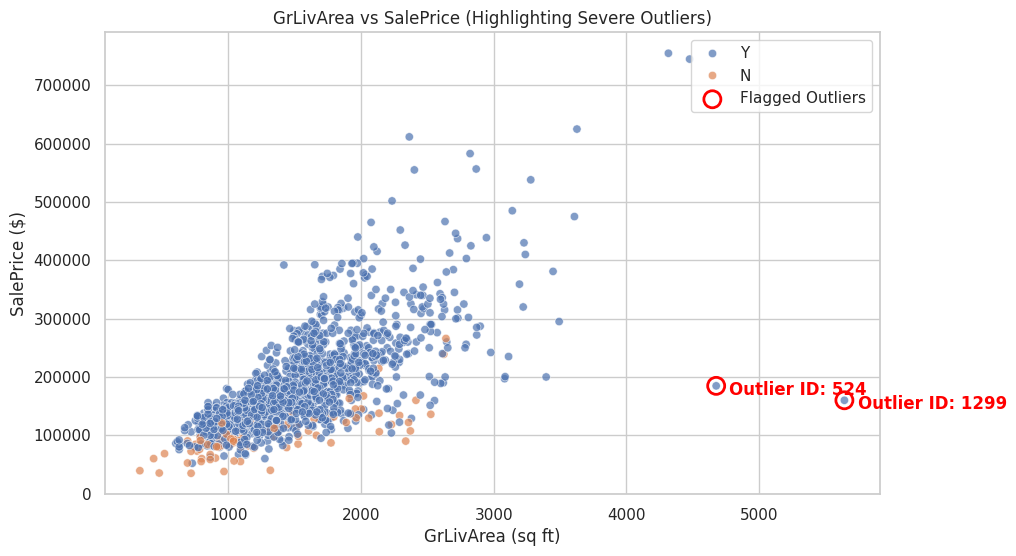

Original dataset size: 1460
Cleaned dataset size: 1458 (Removed IDs: [524, 1299])


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)].index.tolist()

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold].index.tolist()

# Analyze columns of interest
columns_to_check = ['GrLivArea', 'SalePrice']

for col in columns_to_check:
    iqr_idx = iqr_outliers(df[col])
    z_idx = zscore_outliers(df[col])

    overlap = list(set(iqr_idx) & set(z_idx))

    print(f"=== Outlier Detection for {col} ===")
    print(f"IQR Outliers count: {len(iqr_idx)}")
    print(f"Z-score (threshold=3) Outliers count: {len(z_idx)}")
    print(f"Overlap of both methods: {len(overlap)}\n")

# 1. Boxplot showcasing outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, y='GrLivArea', ax=axes[0], color='lightblue')
axes[0].set_title('GrLivArea Outliers')

sns.boxplot(data=df, y='SalePrice', ax=axes[1], color='lightsalmon')
axes[1].set_title('SalePrice Outliers')
plt.tight_layout()
plt.show()

# 2. Scatter plot highlighting anomalies (specifically GrLivArea > 4000 & SalePrice < 300000)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', hue='CentralAir', alpha=0.7)

# Flag outliers based on recommended rules (very large homes sold cheaply)
flagged_outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]
plt.scatter(flagged_outliers['GrLivArea'], flagged_outliers['SalePrice'], color='red', s=150, facecolors='none', edgecolors='red', linewidths=2, label='Flagged Outliers')

for idx, row in flagged_outliers.iterrows():
    plt.text(row['GrLivArea'] + 100, row['SalePrice'] - 15000, f"Outlier ID: {row['Id']}", color='red', weight='bold')

plt.title('GrLivArea vs SalePrice (Highlighting Severe Outliers)')
plt.xlabel('GrLivArea (sq ft)')
plt.ylabel('SalePrice ($)')
plt.legend()
plt.show()

# Decision: Drop the two severe outliers as recommended by the author of the dataset
df_clean = df.drop(index=flagged_outliers.index)
print(f"Original dataset size: {df.shape[0]}")
print(f"Cleaned dataset size: {df_clean.shape[0]} (Removed IDs: {flagged_outliers['Id'].tolist()})")

 Step 9: Data Quality Checks
Goal: Find duplicates, inconsistent labels, and misleading missing values.

In [19]:
import pandas as pd
import numpy as np

# 1. Duplicate check
dup_count = df_clean.duplicated().sum()
print(f"=== Duplicate Rows ===")
print(f"Number of duplicated rows: {dup_count}")
if dup_count > 0:
    df_clean = df_clean.drop_duplicates()
    print(f"Removed duplicates. New shape: {df_clean.shape}")
print()

# 2. Categorical consistency check (Casing, trailing/leading spaces)
print(f"=== Categorical Consistency Checks ===")
issue_found = False
for col in categorical_cols:
    if col in df_clean.columns:
        # Exclude ordinal columns already transformed
        if df_clean[col].dtype.name == 'category':
            continue

        unique_vals = df_clean[col].dropna().unique().tolist()
        # Check if there are values that differ only by case or whitespace
        normalized = [str(val).strip().lower() for val in unique_vals]
        if len(unique_vals) != len(set(normalized)):
            print(f"Possible inconsistent labels in column '{col}': {unique_vals}")
            # Clean up whitespace and standardise casing
            df_clean[col] = df_clean[col].astype(str).str.strip()
            issue_found = True

if not issue_found:
    print("No casing or whitespace issues found in categorical columns.")
print()

# 3. Replace meaningful null values where 'NA' means feature is absent
# For example, PoolQC NaN means 'No Pool'
absent_features_cols = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType']
for col in absent_features_cols:
    if col in df_clean.columns:
        # Fill missing values with 'None'
        if df_clean[col].dtype.name == 'category':
            df_clean[col] = df_clean[col].cat.add_categories('None').fillna('None')
        else:
            df_clean[col] = df_clean[col].fillna('None')

print(f"Filled missing categorical indicators with 'None' for: {absent_features_cols}")
print()

# 4. Handle missing numerical values (e.g. LotFrontage) using Neighborhood median
# Fill LotFrontage with median of its corresponding neighborhood
if 'LotFrontage' in df_clean.columns:
    df_clean['LotFrontage'] = df_clean.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
    # Fallback to overall median if neighborhood has all NaNs
    df_clean['LotFrontage'] = df_clean['LotFrontage'].fillna(df_clean['LotFrontage'].median())
    print("Imputed missing LotFrontage values with neighborhood medians.")

# Fill other remaining missing numerical values with 0 (e.g. MasVnrArea, GarageYrBlt if no garage)
numeric_clean_cols = df_clean.select_dtypes(include=['number']).columns
for col in numeric_clean_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(0)
print()

# 5. Verify remaining missing values count
remaining_missing = df_clean.isnull().sum().sum()
print(f"=== Missing Values Verification ===")
print(f"Total remaining missing values: {remaining_missing}")
if remaining_missing > 0:
    print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print()

# 6. Check for logical anomalies/impossible values
print(f"=== Logical Integrity Checks ===")
impossible_years = df_clean[df_clean['YearBuilt'] > df_clean['YrSold']]
negative_areas = df_clean[(df_clean['LotArea'] < 0) | (df_clean['GrLivArea'] < 0) | (df_clean['TotalBsmtSF'] < 0)]

print(f"Properties built after sold: {len(impossible_years)}")
print(f"Properties with negative area values: {len(negative_areas)}")

=== Duplicate Rows ===
Number of duplicated rows: 0

=== Categorical Consistency Checks ===
No casing or whitespace issues found in categorical columns.

Filled missing categorical indicators with 'None' for: ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType']

Imputed missing LotFrontage values with neighborhood medians.

=== Missing Values Verification ===
Total remaining missing values: 2707
MasVnrType       872
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
GarageFinish      81
GarageQual        81
GarageCond        81
MiscFeature     1404
dtype: int64

=== Logical Integrity Checks ===
Properties built after sold: 0
Properties with negative area values: 0


Step 10: Final Dashboard and Storytelling
Goal: Combine the best visuals into one clean figure and write conclusions.

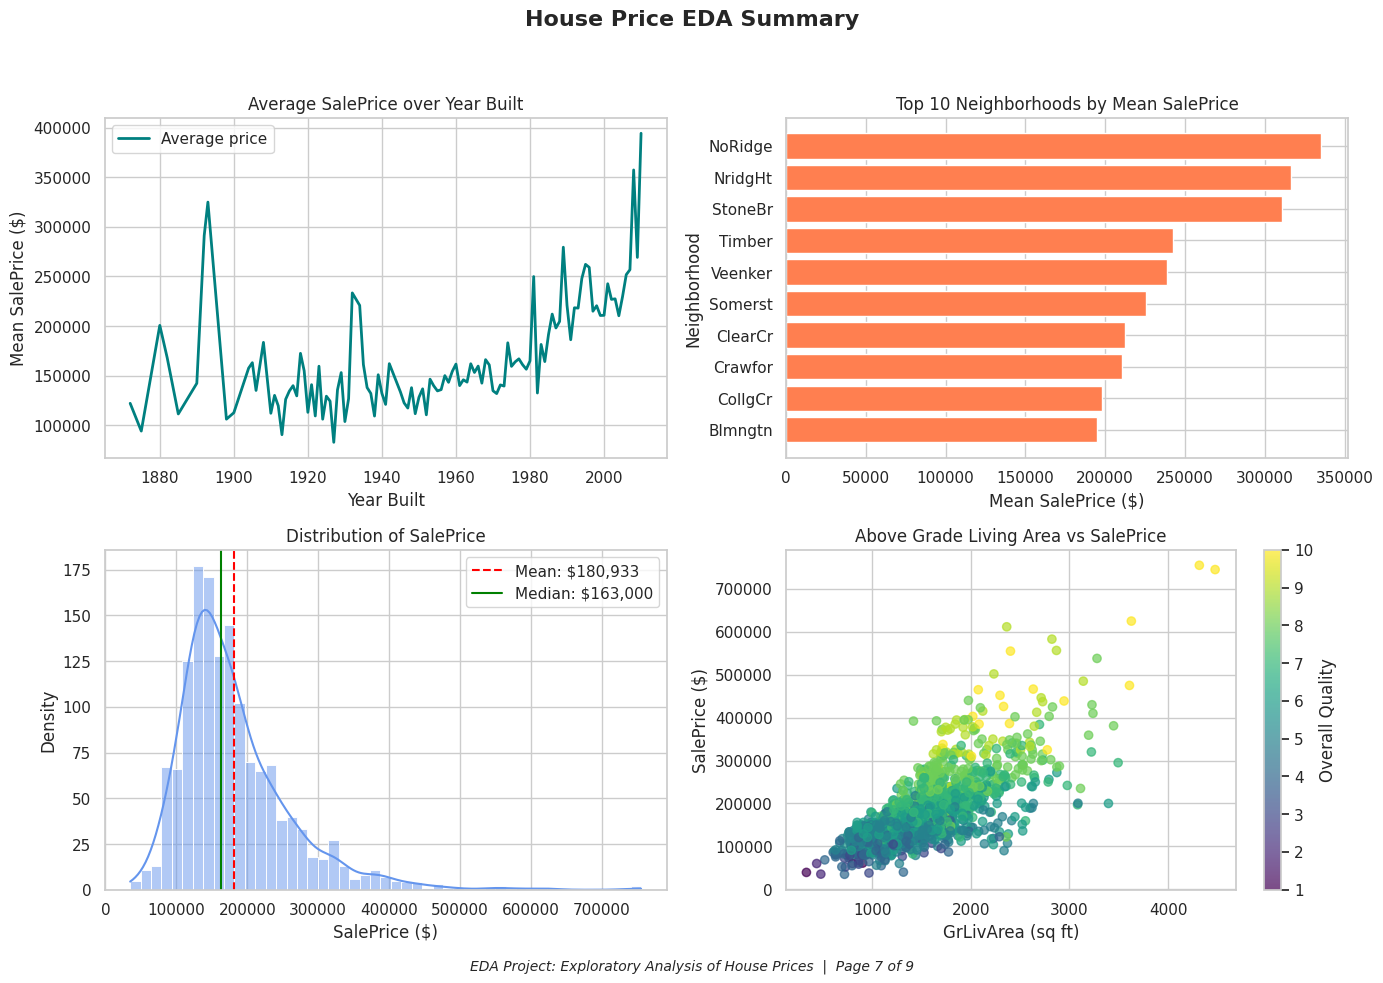

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Ensure we use the cleaned dataset from our previous steps
data_for_plot = df_clean if 'df_clean' in globals() else df

# Create figure with 2 rows x 2 columns, figsize (14, 10)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('House Price EDA Summary', fontsize=16, fontweight='bold')

# Panel 1 (Matplotlib line plot): group by YearBuilt, compute mean SalePrice
year_price = data_for_plot.groupby('YearBuilt')['SalePrice'].mean().reset_index()
axes[0, 0].plot(year_price['YearBuilt'], year_price['SalePrice'], color='teal', label='Average price', linewidth=2)
axes[0, 0].set_title('Average SalePrice over Year Built')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Mean SalePrice ($)')
axes[0, 0].legend()

# Panel 2 (Matplotlib bar plot): group by Neighborhood, mean SalePrice, take top 10
neigh_price = data_for_plot.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False).head(10)
axes[0, 1].barh(neigh_price.index, neigh_price.values, color='coral')
axes[0, 1].invert_yaxis()  # Put the highest neighborhood at the top
axes[0, 1].set_title('Top 10 Neighborhoods by Mean SalePrice')
axes[0, 1].set_xlabel('Mean SalePrice ($)')
axes[0, 1].set_ylabel('Neighborhood')

# Panel 3 (Seaborn histplot with KDE): SalePrice distribution, mark mean and median with vertical lines
sns.histplot(data_for_plot['SalePrice'], kde=True, ax=axes[1, 0], color='cornflowerblue')
mean_val = data_for_plot['SalePrice'].mean()
median_val = data_for_plot['SalePrice'].median()
axes[1, 0].axvline(mean_val, color='red', linestyle='--', label=f'Mean: ${mean_val:,.0f}')
axes[1, 0].axvline(median_val, color='green', linestyle='-', label=f'Median: ${median_val:,.0f}')
axes[1, 0].set_title('Distribution of SalePrice')
axes[1, 0].set_xlabel('SalePrice ($)')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend()

# Panel 4 (Seaborn scatter): GrLivArea vs SalePrice coloured by OverallQual
scatter = axes[1, 1].scatter(
    data_for_plot['GrLivArea'],
    data_for_plot['SalePrice'],
    c=data_for_plot['OverallQual'],
    cmap='viridis',
    alpha=0.7
)
fig.colorbar(scatter, ax=axes[1, 1], label='Overall Quality')
axes[1, 1].set_title('Above Grade Living Area vs SalePrice')
axes[1, 1].set_xlabel('GrLivArea (sq ft)')
axes[1, 1].set_ylabel('SalePrice ($)')

# Set page info / annotation
fig.text(0.5, 0.02, 'EDA Project: Exploratory Analysis of House Prices  |  Page 7 of 9', ha='center', fontsize=10, style='italic')

# Adjust layout, save and show
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('eda_dashboard.png', dpi=300)
plt.show()